# Comparação A/B/C e cinco erros reais

Resultados da nova base documental; este notebook não executa inferência.

,configuration,n,full_correct,answerable_success,correct_refusal,median_seconds,p95_seconds,calls
0,A,60,11,0.00,0.55,2.269663,9.469677,81
1,B,60,39,0.60,0.75,3.195085,6.827421,60
2,C,60,38,0.65,0.60,5.468291,10.168731,231


Alucinação: null é não avaliável; denominadores diferentes não sustentam redução direta.
A T03 Sem contexto, o modelo inventou uma regra de edital e uma transcrição atribuída ao art.46, além de preencher evidence com ID não recebido. O único reparo não resolveu o contrato; a entrega tornou-se indisponivel. Causa provável: combinação de conhecimento gerado sem suporte e baixa adesão à exigência evidence=[] do baseline, não indisponibilidade do servidor. ["status 'indisponivel'; esperado respondido", 'unidades ausentes: 1', 'condições ausentes: 1']
B T01 A única busca top3 trouxe nome social, atraso de entrega e renovação, deixando de fora a FAQ sobre comparecimento pessoal. O modelo usou extratos desses três assuntos como uma resposta parcial, embora nenhum respondesse à possibilidade de representação no cadastramento. Causa provável: similaridade semântica dominada por termos genéricos de Bilhete/posto/cadastro e ausência de verificação de pertinência antes da entrega. ["status 'parcia

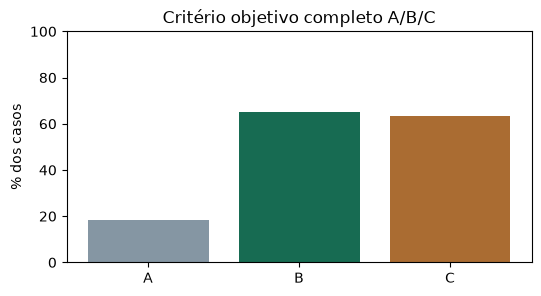

{
  "method": "Juiz automático posterior com a mesma LLM; julgamentos não substituem métricas objetivas.",
  "limitations": [
    "Possível viés de autoavaliação do modelo e erros do próprio juiz.",
    "Não houve revisão humana presumida; null não equivale a ausência de alucinação.",
    "Auditoria limitada às fontes pertinentes e citações identificadas; não avalia verdade universal.",
    "Tempo e tokens do juiz são separados da latência/custo da tarefa medida."
  ],
  "configurations": {
    "A": {
      "n": 60,
      "technical_judge_failures": 0,
      "raw": {
        "task_success": {
          "numerator": 5,
          "denominator": 60,
          "rate": 0.08333333333333333,
          "not_evaluable": 0
        },
        "hallucination": {
          "numerator": 34,
          "denominator": 43,
          "rate": 0.7906976744186046,
          "not_evaluable": 17
        },
        "citation_sufficient": {
          "numerator": 5,
          "denominator": 60,
          "rate"

In [1]:
from pathlib import Path
import json,pandas as pd
ROOT=Path.cwd().parent if Path.cwd().name=="notebooks" else Path.cwd()
run=ROOT/"avaliacao/resultados/20261112T061006Z-teste"
s=json.loads((run/"summary.json").read_text(encoding="utf8"))
display(pd.DataFrame([{"configuration":cfg,"n":v["n"],"full_correct":v["full_correct"]["sum"],"answerable_success":v["answerable_success"]["mean"],"correct_refusal":v["correct_refusal"]["mean"],"median_seconds":v["latency_seconds"]["median"],"p95_seconds":v["latency_seconds"]["p95"],"calls":v["calls"]} for cfg,v in s.items()]))
print("Alucinação: null é não avaliável; denominadores diferentes não sustentam redução direta.")
errors=json.loads((ROOT/"avaliacao/erros_reais.json").read_text(encoding="utf8"))
for e in errors:print(e["result"]["configuration"],e["case"]["id"],e["probable_cause"],e["result"]["score"]["judgment_reasons"])
import matplotlib.pyplot as plt
fig,ax=plt.subplots(figsize=(6,3))
ax.bar(list(s),[100*v["full_correct"]["mean"] for v in s.values()],color=["#8596a3","#176b52","#aa6c32"])
ax.set(ylabel="% dos casos",title="Critério objetivo completo A/B/C",ylim=(0,100))
plt.show()
audit=run/"auditoria_semantica/resumo.json"
if audit.exists(): print(audit.read_text(encoding="utf8"))